# **Social Media Sentiment Analysis Using Twitter Data**



---



**Objective**

Analyse sentiment patterns in Twitter data to understand how opinions vary across entities, topics and sentiment categories.



---


**Key Questions**

1. What proportion of tweets are positive, negative, neutral or classified as irrelevant?

2. Which entities have the highest positive and negative sentiment counts?

3. How does sentiment distribution vary between entities?

4. What words and phrases are frequently associated with each sentiment?

5. How well can a machine-learning model classify sentiment on separate validation data?



---


**Tools**

Python, SQL, Excel & Tableau



---


**Workflow**

Data loading -> Data quality checks -> Data cleaning -> Exploratory data analysis -> Sentiment visualization -> Optional model evaluation -> Reporting and dashboard development

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported!")

Libraries imported!


In [2]:
training_file = "twitter_training.csv"
validation_file = "twitter_validation.csv"

training_df = pd.read_csv(training_file, header=None)
validation_df = pd.read_csv(validation_file, header=None)

print("Training shape:", training_df.shape)
print("Validation shape:", validation_df.shape)

Training shape: (74682, 4)
Validation shape: (1000, 4)


In [3]:
display(training_df.head())
display(validation_df.head())

,0,1,2,3
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


,0,1,2,3
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...


In [4]:
print("Training columns:", training_df.columns.tolist())
print("Validation columns:", validation_df.columns.tolist())

Training columns: [0, 1, 2, 3]
Validation columns: [0, 1, 2, 3]


In [6]:
expected_columns = ["id", "entity", "sentiment", "text"]

if training_df.shape[1] == 4 and validation_df.shape[1] == 4:
    training_df.columns = expected_columns
    validation_df.columns = expected_columns
    print("Column names assigned successfully!")
    print("Columns:", training_df.columns.tolist())
else:
    print(f"Expected 4 columns, but training has {training_df.shape[1]} and validation has {validation_df.shape[1]}.")

Column names assigned successfully!
Columns: ['id', 'entity', 'sentiment', 'text']


In [7]:
print("Training dataset information:")
training_df.info()

print("\nValidation dataset information:")
validation_df.info()

print("\nMissing values in training dataset:")
print(training_df.isnull().sum())

print("\nMissing values in validation dataset:")
print(validation_df.isnull().sum())

print("\nDuplicate rows in training data:", training_df.duplicated().sum())

Training dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         74682 non-null  int64 
 1   entity     74682 non-null  object
 2   sentiment  74682 non-null  object
 3   text       73996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB

Validation dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         1000 non-null   int64 
 1   entity     1000 non-null   object
 2   sentiment  1000 non-null   object
 3   text       1000 non-null   object
dtypes: int64(1), object(3)
memory usage: 31.4+ KB

Missing values in training dataset:
id             0
entity         0
sentiment      0
text         686
dtype: int64

Missing values in validation dataset

In [9]:
print(training_df["sentiment"].value_counts(dropna=False))

sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64


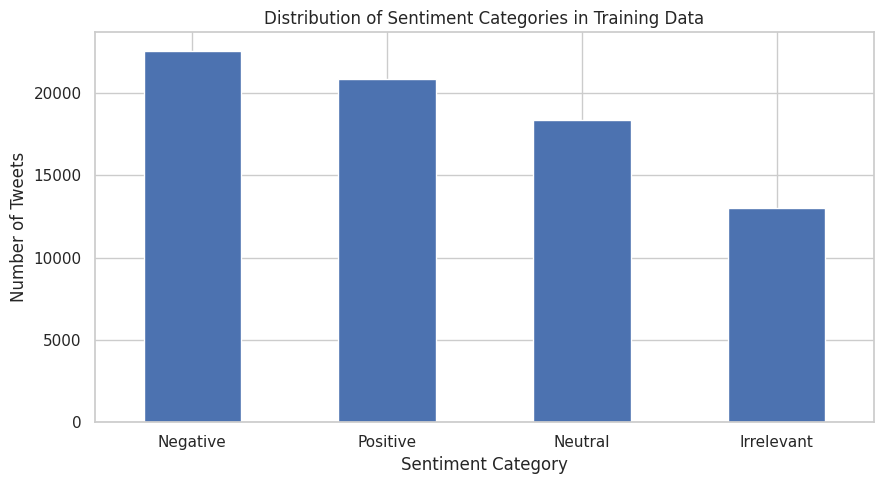

In [10]:
sentiment_counts = training_df["sentiment"].value_counts()

sentiment_counts.plot(kind="bar", figsize=(9,5))

plt.title("Distribution of Sentiment Categories in Training Data")
plt.xlabel("Sentiment Category")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
entity_sentiment = pd.crosstab(training_df["entity"], training_df["sentiment"])

display(entity_sentiment.head(10))

sentiment,Irrelevant,Negative,Neutral,Positive
entity,,,,
Amazon,192,576,1236,312
ApexLegends,192,600,942,642
AssassinsCreed,264,378,156,1446
Battlefield,918,474,360,594
Borderlands,240,426,600,1020
CS-GO,636,348,552,768
CallOfDuty,672,894,378,450
CallOfDutyBlackopsColdWar,576,576,360,864
Cyberpunk2077,480,390,468,966


In [13]:
training_clean = training_df.copy()
validation_clean = validation_df.copy()

for data in [training_clean, validation_clean]:
    data["sentiment"] = data["sentiment"].astype("string").str.strip().str.lower()
    data["text"] = data["text"].astype("string").str.strip()
    data["entity"] = data["entity"].astype("string").str.strip()

    data.replace({"": pd.NA, "nan": pd.NA}, inplace=True)

    data.dropna(subset = ["sentiment", "text"], inplace=True)

print("Training data after cleaning:", training_clean.shape)
print("Validation data after cleaning:", validation_clean.shape)

display(training_clean.head())

Training data after cleaning: (73824, 4)
Validation data after cleaning: (1000, 4)


,id,entity,sentiment,text
0,2401,Borderlands,positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,positive,im getting on borderlands 2 and i will murder ...


,count,mean,median
sentiment,,,
irrelevant,12842,111.11,93.0
negative,22312,111.45,91.0
neutral,18051,119.06,105.0
positive,20619,95.99,75.0


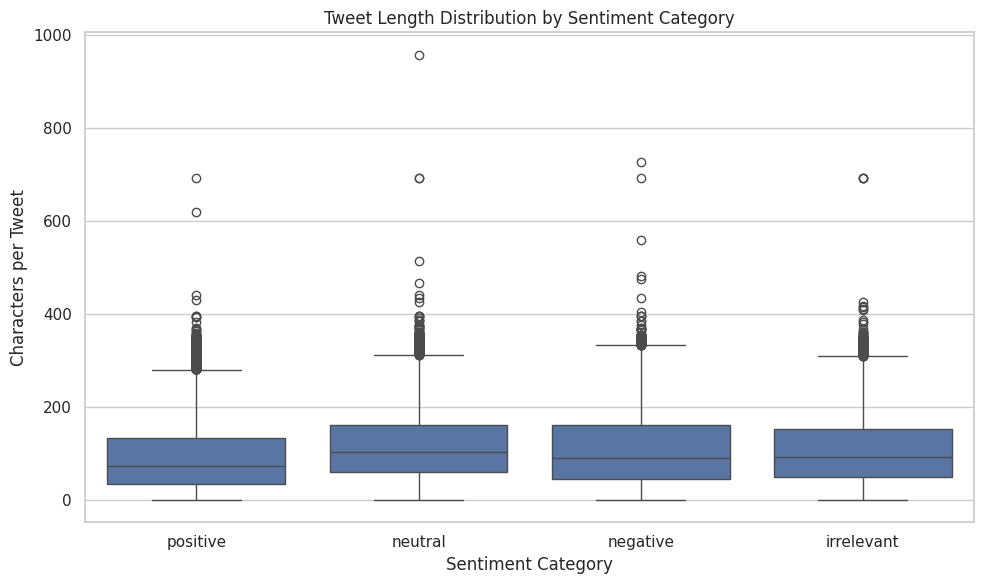

In [15]:
training_clean["tweet_length"] = training_clean["text"].str.len()
validation_clean["tweet_length"] = validation_clean["text"].str.len()

display(training_clean.groupby("sentiment")["tweet_length"].agg(["count", "mean", "median"]).round(2))

sns.boxplot(data=training_clean, x="sentiment", y="tweet_length")
plt.title("Tweet Length Distribution by Sentiment Category")
plt.xlabel("Sentiment Category")
plt.ylabel("Characters per Tweet")
plt.tight_layout()
plt.show()

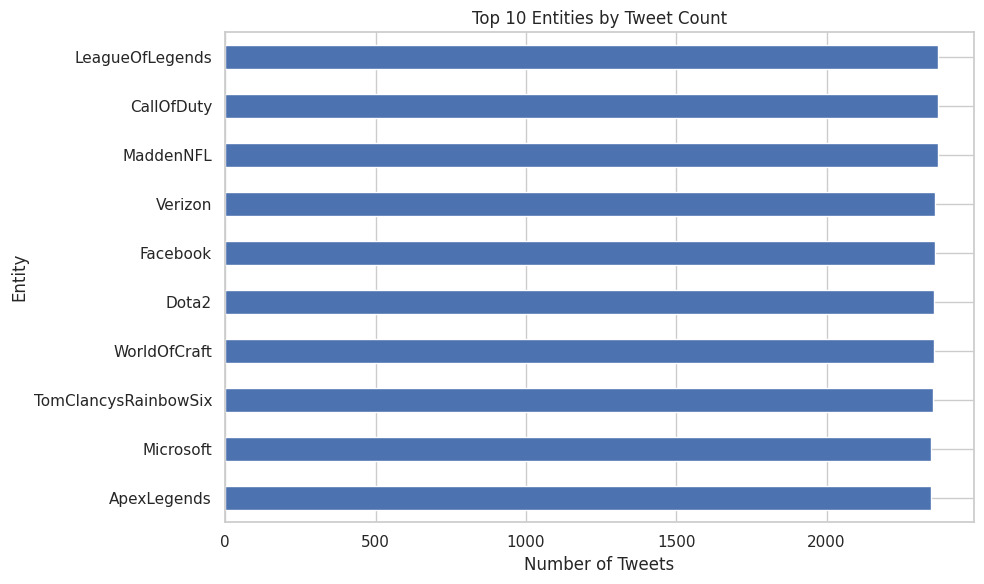

In [16]:
top_entities = training_clean["entity"].value_counts().head(10)

top_entities.sort_values().plot(kind="barh")

plt.title("Top 10 Entities by Tweet Count")
plt.xlabel("Number of Tweets")
plt.ylabel("Entity")
plt.tight_layout()
plt.show()

sentiment,irrelevant,negative,neutral,positive
entity,,,,
Amazon,8.1,25.4,52.9,13.6
ApexLegends,8.2,25.1,39.8,26.9
AssassinsCreed,11.8,16.8,7.0,64.4
Battlefield,39.6,20.0,15.1,25.3
Borderlands,10.5,18.7,26.2,44.6
CS-GO,27.7,15.0,24.0,33.3
CallOfDuty,28.3,37.1,15.8,18.8
CallOfDutyBlackopsColdWar,24.3,24.1,15.0,36.6
Cyberpunk2077,20.4,17.1,20.4,42.0


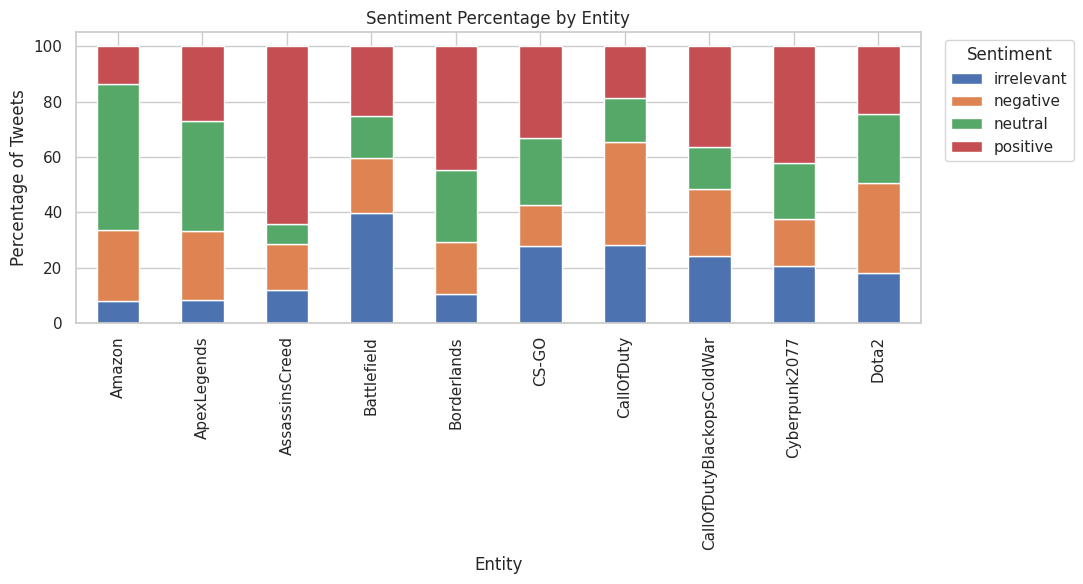

In [17]:
entity_sentiment_pct = pd.crosstab(training_clean["entity"], training_clean["sentiment"], normalize="index") * 100

display(entity_sentiment_pct.head(10).round(1))

entity_sentiment_pct.head(10).plot(kind="bar", stacked=True, figsize=(11,6))

plt.title("Sentiment Percentage by Entity")
plt.xlabel("Entity")
plt.ylabel("Percentage of Tweets")
plt.legend(title="Sentiment", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

x_train = training_clean["text"]
y_train = training_clean["sentiment"]

x_val = validation_clean["text"]
y_val = validation_clean["sentiment"]

vectorizer = TfidfVectorizer(stop_words="english", max_features=20000)

x_train_tfidf = vectorizer.fit_transform(x_train)
x_val_tfidf = vectorizer.transform(x_val)

model = LogisticRegression(max_iter=1000)
model.fit(x_train_tfidf, y_train)

y_pred = model.predict(x_val_tfidf)

print("Classification Report:")
print(classification_report(y_val, y_pred))

print("\n Validation Accuracy:", accuracy_score(y_val, y_pred))

Classification Report:
              precision    recall  f1-score   support

  irrelevant       0.92      0.90      0.91       172
    negative       0.88      0.95      0.92       266
     neutral       0.94      0.89      0.92       285
    positive       0.92      0.91      0.92       277

    accuracy                           0.92      1000
   macro avg       0.92      0.92      0.92      1000
weighted avg       0.92      0.92      0.92      1000


 Validation Accuracy: 0.916


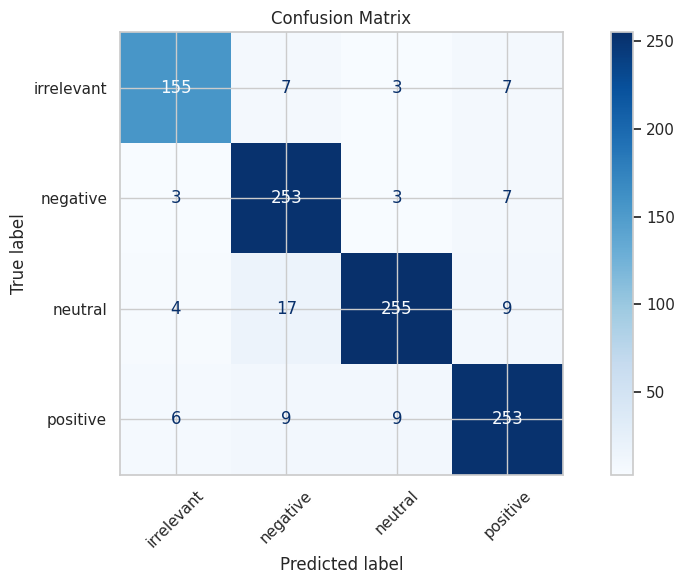

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = sorted(y_train.unique())

cm = confusion_matrix(y_val, y_pred, labels=labels)

display_labels = labels

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=display_labels)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [23]:
results = validation_clean[["id", "entity", "sentiment", "text"]].copy()

results["Predicted Sentiment"] = y_pred
results["Correct_Prediction"] = (results["sentiment"] == results["Predicted Sentiment"])

display(results.head(10))

training_clean.to_csv("twitter_training_cleaned.csv", index=False)
validation_clean.to_csv("twitter_validation_cleaned.csv", index=False)
results.to_csv("twitter_validation_predictions.csv", index=False)
entity_sentiment_pct.to_csv("entity_sentiment_percentages.csv")
print("CSV files exported!")

,id,entity,sentiment,text,Predicted Sentiment,Correct_Prediction
0,3364,Facebook,irrelevant,I mentioned on Facebook that I was struggling ...,irrelevant,True
1,352,Amazon,neutral,BBC News - Amazon boss Jeff Bezos rejects clai...,neutral,True
2,8312,Microsoft,negative,@Microsoft Why do I pay for WORD when it funct...,negative,True
3,4371,CS-GO,negative,"CSGO matchmaking is so full of closet hacking,...",negative,True
4,4433,Google,neutral,Now the President is slapping Americans in the...,neutral,True
5,6273,FIFA,negative,Hi @EAHelp I’ve had Madeleine McCann in my cel...,negative,True
6,7925,MaddenNFL,positive,Thank you @EAMaddenNFL!! New TE Austin Hoope...,positive,True
7,11332,TomClancysRainbowSix,positive,"Rocket League, Sea of Thieves or Rainbow Six: ...",irrelevant,False
8,1107,AssassinsCreed,positive,my ass still knee-deep in Assassins Creed Odys...,positive,True
9,2069,CallOfDuty,negative,FIX IT JESUS ! Please FIX IT ! What In the wor...,negative,True


CSV files exported!


**Conclusion**

This project explored social media sentiment using Python. The analysis included dataset inspection, data quality checks, sentiment distribution, comparisons across entities, and tweet-length analysis.

The exploratory analysis helped identify the distribution of sentiment categories and differences in sentiment patterns across entities. A TF-IDF and Logistic Regress model was then trained on the the training dataset and evaluated using the separate validation dataset.

The classification report and confusion matrix were used to examine its performance across sentiment categories.

Overall, this project provided practical experience in data cleaning, exploratory data analysis, text processing, machine learning, model evaluation, and data visualization. The exported datasets and predictions can support further analysis using SQL, Excel and Tableau.



---



**Limitations**

The results depend on the dataset's labels, quality and representation of social media text. Model accuracy alone does not fully describe performance across all sentiment categories.